# Analisis EDA: OnLine Retail II

## 1. Carga de Datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.options.display.float_format = '{:,.2f}'.format

df=pd.read_csv("../data/online_retail_II.csv")
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom


> **Hallazgo:** dataset cargado con 8 columnas. Cada fila es un producto vendido dentro de una factura.

## 2. Estructura del dataset

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  str    
 1   StockCode    1067371 non-null  str    
 2   Description  1062989 non-null  str    
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  str    
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 65.1 MB


> **Hallazgo:** 1.067.371 filas. `Customer ID` tiene 243.007 nulos (~22%) y `Description` 4.382 nulos.

## 3. Filtrado de clientes sin ID

In [3]:
df_clean = df.dropna(subset=['Customer ID'])
df_clean['Customer ID'] = df_clean['Customer ID'].astype(int)
df_clean.shape

(824364, 8)

> **Hallazgo:** quedan 824.364 filas. Se descartan las filas sin cliente porque no permiten analizar comportamiento de compra.

## 4. Valores negativos

In [4]:
print(df_clean[df_clean['Quantity'] < 0].shape)
print(df_clean[df_clean['Price'] < 0].shape)

(18744, 8)
(0, 8)


> **Hallazgo:** 18.744 filas con `Quantity` negativa. No hay precios negativos.

## 5. Cancelaciones

In [5]:
df_clean[df_clean['Quantity'] < 0].head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321,Australia


> **Hallazgo:** las facturas con cantidad negativa empiezan con "C", son devoluciones. Se analizarán por separado de las ventas.

## 6. Duplicados y formato de fecha

In [6]:
duplicados = df_clean.duplicated().sum()
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])
print(duplicados)
df_clean.dtypes

26479


Invoice                   str
StockCode                 str
Description               str
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID             int64
Country                   str
dtype: object

> **Hallazgo:** 26.479 filas duplicadas. `InvoiceDate` convertida a datetime.

## 7. Inspección de duplicados

In [7]:
dups = df_clean[df_clean.duplicated(keep=False)]
dups.sort_values(['Invoice','StockCode']).head(20)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329,United Kingdom
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom
394,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329,United Kingdom
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329,United Kingdom


> **Hallazgo:** son líneas idénticas dentro de la misma factura. Se eliminarán para no inflar cantidades ni ingresos.

## 8. Eliminación de duplicados

In [8]:
df_clean = df_clean.drop_duplicates()
df_clean.shape

(797885, 8)

> **Hallazgo:** Se eliminaron los duplicados y quedaron 797.885 filas

## 9. Estadisticas descriptivas

In [9]:
df_clean[['Quantity', 'Price']].describe()

,Quantity,Price
count,"797,885.00","797,885.00"
mean,12.60,3.70
std,191.67,71.39
min,"-80,995.00",0.00
25%,2.00,1.25
50%,5.00,1.95
75%,12.00,3.75
max,"80,995.00","38,970.00"


> **Hallazgo:**
> - **Precios en 0:** existen productos con `Price` = 0. Pueden ser regalos, muestras o errores; se revisarán.
> - **Outliers:** el 75% de las filas tiene hasta 12 unidades y £3.75, pero los máximos llegan a 80.995 unidades y £38.970.
> - **Asimetría:** el promedio duplica a la mediana (`Quantity` 12.6 vs 5; `Price` 3.70 vs 1.95). La mayoría de las compras son chicas y pocas compras grandes inflan el promedio. Se usará la **mediana** como valor típico.

## 10. Verificación de outlier en Quantity

In [10]:
df_clean[df_clean['Quantity'].abs() == 80995]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446,United Kingdom
1065883,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446,United Kingdom


> **Hallazgo:**
> - Compra: `Invoice` 581483 , 80995 unidades de `StockCode` 23843 ,`Description` PAPER CRAFT, LITTLE BIRDIE, `Price` £2,08 a las 09:15 HS
> - Devolución: `Invoice` C581484  , mismas unidades, a las 09:27 HS
> - Conclusión: Rechazaron el pedido 12 minutos después de la compra,  aparentemente "error de carga"
> - Decisión: Se eliminan ambas filas para que podamos seguir haciendo el análisis ya que se entiende como un error humano

## 11. Eliminación del outlier de Quantity

In [11]:
df_clean = df_clean.drop([1065882, 1065883])
df_clean.shape

(797883, 8)

> **Hallazgo:**
> - Se eliminó la compra `Invoice` 581483 y `Invoice` C581484 ya que se presume que fue un fallo humano
> - Quedaron 797.883 filas

## 12. Productos con precio 0

In [12]:
df_clean[df_clean['Price']==0]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
4674,489825,22076,6 RIBBONS EMPIRE,12,2009-12-02 13:34:00,0.00,16126,United Kingdom
6781,489998,48185,DOOR MAT FAIRY CAKE,2,2009-12-03 11:19:00,0.00,15658,United Kingdom
16107,490727,M,Manual,1,2009-12-07 16:38:00,0.00,17231,United Kingdom
18738,490961,22065,CHRISTMAS PUDDING TRINKET POT,1,2009-12-08 15:25:00,0.00,14108,United Kingdom
18739,490961,22142,CHRISTMAS CRAFT WHITE FAIRY,12,2009-12-08 15:25:00,0.00,14108,United Kingdom
...,...,...,...,...,...,...,...,...
1004540,577129,22464,HANGING METAL HEART LANTERN,4,2011-11-17 19:52:00,0.00,15602,United Kingdom
1005014,577168,M,Manual,1,2011-11-18 10:42:00,0.00,12603,Germany
1006110,577314,23407,SET OF 2 TRAYS HOME SWEET HOME,2,2011-11-18 13:23:00,0.00,12444,Norway
1011446,577696,M,Manual,1,2011-11-21 11:57:00,0.00,16406,United Kingdom


> **Hallazgo:**
> - Se hallaron 70 filas con `Price` 0 de 797.883 filas que es el 0,01% del total y algunas con `StockCode` M se entiende que es un cambio manual y algunos son regalos, no se tendran en cuenta para el resto del analisis

## 13.  Eliminación de productos con precios 0

In [13]:
df_clean = df_clean[df_clean['Price'].abs() > 0]
df_clean.shape

(797813, 8)

> **Hallazgo:**
> - Se eliminarion filas con `Price` igual a 0 y quedaron 797.813 filas

## 14. Separación de ventas y devoluciones

In [14]:
ventas = df_clean[df_clean['Quantity'] > 0]
devoluciones = df_clean[df_clean['Quantity'] < 0]
print("Devoluciones", devoluciones.shape)
print("Ventas", ventas.shape)
print("Total", ventas.shape[0] + devoluciones.shape[0])

Devoluciones (18389, 8)
Ventas (779424, 8)
Total 797813


> **Hallazgo:**
> - Devoluciones: tiene 18.389 filas
> - Ventas: tiene 779.424 filas 
> - Comprobación: la suma de ventas y devoluciones da 797.813, igual que `df_clean`. No hay filas con `Quantity` igual a 0.
> - Interpretación: las devoluciones son solo el 2,30% del total, un porcentaje bajo. El análisis de ingresos se hará sobre la tabla ventas.

## 15. Ingresos por linea de ventas

In [15]:
ventas['TotalPrice'] = ventas['Quantity'] * ventas['Price']
ventas['TotalPrice'].describe()


count   779,424.00
mean         22.08
std         123.77
min           0.00
25%           4.95
50%          12.48
75%          19.80
max      77,183.60
Name: TotalPrice, dtype: float64

> **Hallazgo:**
> - **Asimetria:** Se encontro una media de 22,08 que duplica a la mediana de 12,48 y con un minimo de 0,001 y un maximo de 77.183,60 que es sospechoso y se revisara
> - El 75% de las lineas de ventas no superan los £19,80

## 16. Verificación de outlier en TotalPrice

In [16]:
ventas[ventas['TotalPrice'] == 77183.6].style.format({'Price': '£{:,.2f}', 'TotalPrice': '£{:,.2f}'})


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalPrice
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,£1.04,12346,United Kingdom,"£77,183.60"


In [17]:
devoluciones[(devoluciones['StockCode'] == '23166') & (devoluciones['Customer ID'] == 12346)].style.format({'Price': '£{:,.2f}'})

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
587085,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,£1.04,12346,United Kingdom


> **Hallazgo:**
> - **Venta:** `Invoice` 541431, `Quantity` 74215, `StockCode` 23166, `Price` 1.04, `InvoiceDate` 2011-01-18 10:01HS
> - **Devolución:** `Invoice` C541433, misma cantidad, `InvoiceDate` 2011-01-18 10:17HS
> - **Conclusión:**  La devolución se hizo a los 16 minutos posteriores, esto da a entender que es la devolución de la venta anteriormente visualizada 
> - **Decisión:** Eliminar de ventas y de devoluciones ya que se presume que fue un fallo humano

## 17. Eliminación del outlier de TotalPrice

In [18]:
ventas = ventas.drop(587080)
ventas.shape

(779423, 9)

In [19]:
devoluciones = devoluciones.drop(587085)
devoluciones.shape

(18388, 8)

> **Hallazgo:**
> - Se eliminaron las filas 587.080 de ventas y la fila 587.085 de devoluciones
> - **Ventas:** quedo con 779.423 filas
> - **Devoluciones:** quedo con 18.388 filas

## 18. KPI generales de ventas

In [20]:
ingresos_totales = ventas['TotalPrice'].sum()
n_facturas = ventas['Invoice'].nunique()
n_clientes = ventas['Customer ID'].nunique()
n_productos = ventas['StockCode'].nunique()
frecuencia = n_facturas / n_clientes

In [21]:
print(f"Los ingresos totales son: £{ingresos_totales:,.2f}")
print(f"El número total de facturas es: {n_facturas:,}")
print(f"El número total de clientes es: {n_clientes:,}")
print(f"El número total de productos es: {n_productos:,}")
print(f"La frecuencia de compra promedio por cliente es: {frecuencia:.1f}")

Los ingresos totales son: £17,129,151.07
El número total de facturas es: 36,967
El número total de clientes es: 5,878
El número total de productos es: 4,630
La frecuencia de compra promedio por cliente es: 6.3


In [22]:
ticket = ventas.groupby('Invoice')['TotalPrice'].sum()
ticket.describe()

count   36,967.00
mean       463.36
std        962.42
min          0.38
25%        157.91
50%        303.04
75%        477.20
max     44,051.60
Name: TotalPrice, dtype: float64

> **Hallazgo:**
> - **Ingresos totales:** £17,129,151.07
> - **Facturas:** 36,967 | **Clientes:** 5,878 | **Productos:** 4,630
> - **Frecuencia:** 6,3 compras por cliente en 2 años: clientes recurrentes
> - **Ticket por factura:** media £463,36 vs mediana £303,04
> - **Interpretación:** El perfil sugiere clientes mayoristas: ticket típico £303 y 6,3 compras por clientes, pocas facturas muy grandes que elevan la media a £463.

## 19. Evolución mensual de ingresos

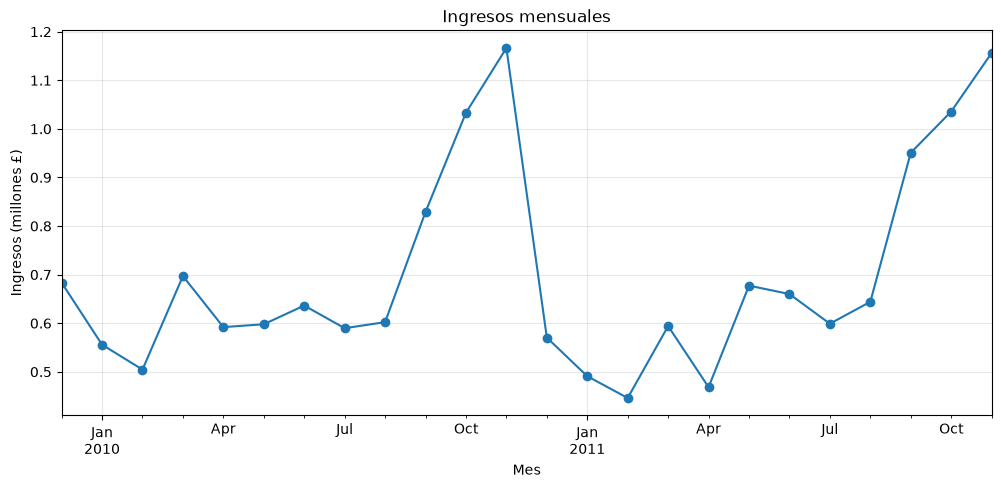

InvoiceDate
2010-11   1,166,460.02
2011-11   1,156,205.61
2011-10   1,035,642.45
Freq: M, Name: TotalPrice, dtype: float64
InvoiceDate
2011-02   446,084.92
2011-04   468,374.33
2011-01   490,917.71
Freq: M, Name: TotalPrice, dtype: float64


In [24]:
ventas_mes = ventas.groupby(ventas['InvoiceDate'].dt.to_period('M'))['TotalPrice'].sum()
ventas_mes = ventas_mes[ventas_mes.index < '2011-12']  # dic-2011 incompleto (termina el 9/12)

(ventas_mes / 1_000_000).plot(kind='line', figsize=(12, 5), marker='o')
plt.title('Ingresos mensuales')
plt.xlabel('Mes')
plt.ylabel('Ingresos (millones £)')
plt.grid(alpha=0.3)
plt.show()

print(ventas_mes.sort_values(ascending=False).head(3))
print(ventas_mes.sort_values().head(3))

> **Hallazgo:**
> - **Pico:** noviembre en ambos años: £1.166.460 (2010) y £1.156.206 (2011). Le sigue octubre 2011 con £1.035.642.
> - **Estacionalidad:** el patrón se repite. Los ingresos suben desde septiembre y tocan el máximo en noviembre.
> - **Valle:** los meses más bajos son de principio de año: febrero 2011 (£446.085), abril 2011 (£468.374) y enero 2011 (£490.918).
> - **Interpretación:** el pico en noviembre y no en diciembre confirma el perfil mayorista. Los clientes compran stock antes de Navidad para revenderlo.
> - **Nota:** diciembre 2011 se excluyó porque el dataset termina el 09/12/2011.

## 20. Productos más vendidos

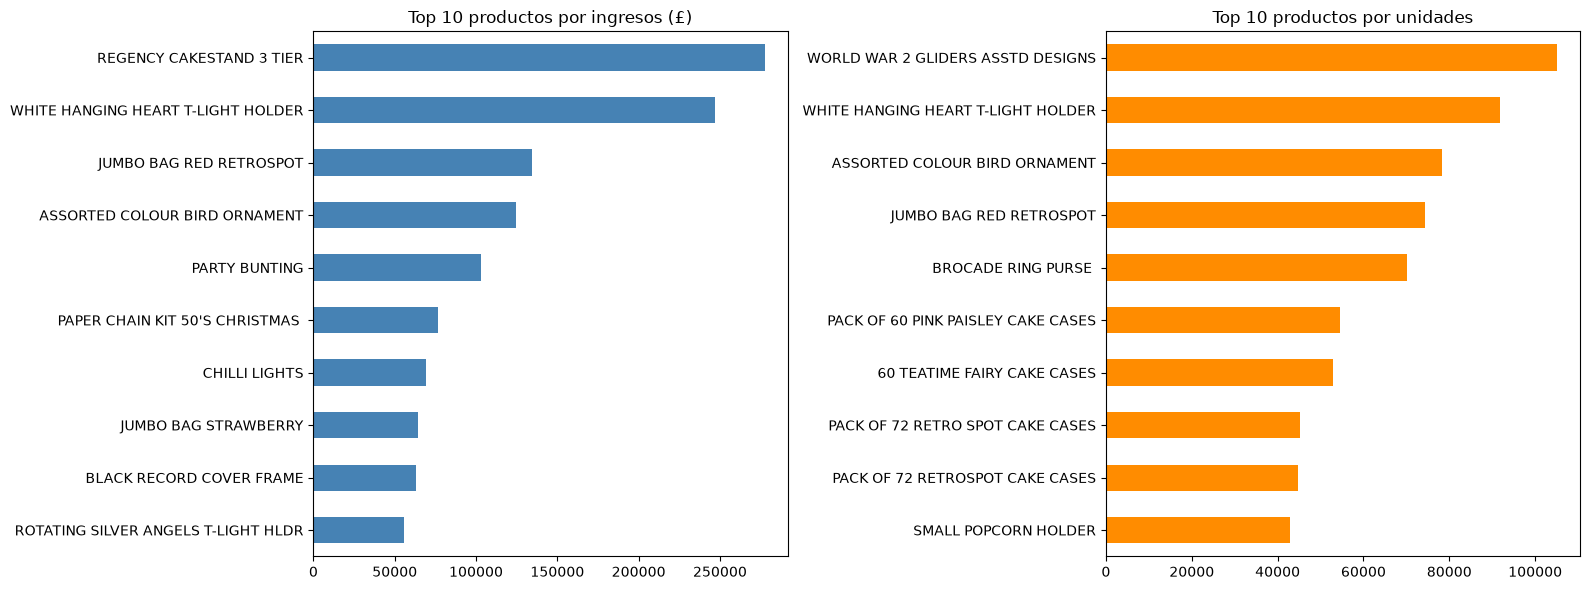

Description
REGENCY CAKESTAND 3 TIER              277,656.25
WHITE HANGING HEART T-LIGHT HOLDER    247,048.01
JUMBO BAG RED RETROSPOT               134,307.44
ASSORTED COLOUR BIRD ORNAMENT         124,351.86
PARTY BUNTING                         103,283.38
PAPER CHAIN KIT 50'S CHRISTMAS         76,598.18
CHILLI LIGHTS                          69,084.30
JUMBO BAG STRAWBERRY                   64,127.77
BLACK RECORD COVER FRAME               63,092.12
ROTATING SILVER ANGELS T-LIGHT HLDR    55,880.17
Name: TotalPrice, dtype: float64 

Description
WORLD WAR 2 GLIDERS ASSTD DESIGNS     105185
WHITE HANGING HEART T-LIGHT HOLDER     91757
ASSORTED COLOUR BIRD ORNAMENT          78234
JUMBO BAG RED RETROSPOT                74224
BROCADE RING PURSE                     70082
PACK OF 60 PINK PAISLEY CAKE CASES     54592
60 TEATIME FAIRY CAKE CASES            52828
PACK OF 72 RETRO SPOT CAKE CASES       45129
PACK OF 72 RETROSPOT CAKE CASES        44721
SMALL POPCORN HOLDER                   42955
N

In [29]:
productos = ventas[~ventas['Description'].isin(['Manual', 'POSTAGE'])]
top_ingresos = productos.groupby('Description')['TotalPrice'].sum().nlargest(10)
top_cantidad = productos.groupby('Description')['Quantity'].sum().nlargest(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
top_ingresos.sort_values().plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('Top 10 productos por ingresos (£)')
axes[0].set_ylabel('')
top_cantidad.sort_values().plot(kind='barh', ax=axes[1], color='darkorange')
axes[1].set_title('Top 10 productos por unidades')
axes[1].set_ylabel('')
plt.tight_layout()
plt.show()

print(top_ingresos, "\n")
print(top_cantidad, "\n")
print("En ambos tops:", set(top_ingresos.index) & set(top_cantidad.index))

> **Hallazgo:**
> - **Exclusión:** se quitaron `Manual` (ajustes manuales, StockCode M) y `POSTAGE` (costo de envío) porque no son productos vendidos.
> - **Top ingresos:** lidera REGENCY CAKESTAND 3 TIER (£277.656) seguido de WHITE HANGING HEART T-LIGHT HOLDER (£247.048).
> - **Top unidades:** lidera WORLD WAR 2 GLIDERS ASSTD DESIGNS (105.185 unidades), pero no aparece en el top de ingresos porque su precio unitario es bajo.
> - **En ambos tops:** WHITE HANGING HEART T-LIGHT HOLDER, JUMBO BAG RED RETROSPOT y ASSORTED COLOUR BIRD ORNAMENT. Combinan volumen alto y buen precio: son los productos clave del negocio.
> - **Calidad de datos:** "PACK OF 72 RETRO SPOT CAKE CASES" y "PACK OF 72 RETROSPOT CAKE CASES" parecen el mismo producto escrito de dos formas.
> - **Interpretación:** predominan artículos de decoración y bolsas de bajo precio que se compran en volumen, coherente con el perfil mayorista visto en las secciones 18 y 19.

## 21. Ingresos por país

In [26]:
ingresos_pais = ventas.groupby('Country')['TotalPrice'].sum().sort_values(ascending=False)

n_paises = ventas['Country'].nunique()
pct_uk = ingresos_pais['United Kingdom'] / ingresos_pais.sum() * 100

print(f"Número de países: {n_paises}")
print(f"Ingresos UK: £{ingresos_pais['United Kingdom']:,.2f} ({pct_uk:.1f}% del total)")

Número de países: 41
Ingresos UK: £14,143,581.72 (82.6% del total)


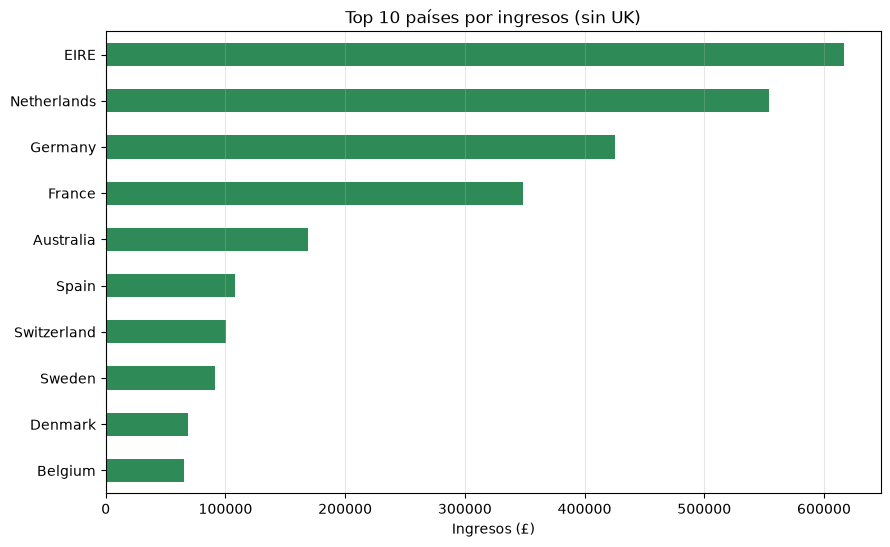

Country
EIRE          616,570.54
Netherlands   554,038.09
Germany       425,019.71
France        348,768.96
Australia     169,283.46
Spain         108,332.49
Switzerland   100,061.94
Sweden         91,515.82
Denmark        68,580.69
Belgium        65,387.82
Name: TotalPrice, dtype: float64
Resto de países (sin UK): 17.4%
Country
EIRE          3.60
Netherlands   3.20
Germany       2.50
France        2.00
Australia     1.00
Spain         0.60
Switzerland   0.60
Sweden        0.50
Denmark       0.40
Belgium       0.40
Name: TotalPrice, dtype: float64


In [ ]:
top_paises = ingresos_pais.drop('United Kingdom').head(10)

top_paises.sort_values().plot(kind='barh', figsize=(10, 6), color='seagreen')
plt.title('Top 10 países por ingresos (sin UK)')
plt.xlabel('Ingresos (£)')
plt.ylabel('')
plt.grid(axis='x', alpha=0.3)
plt.show()

print(top_paises)

In [30]:
pct_paises = ingresos_pais / ingresos_pais.sum() * 100

print(f"Resto de países (sin UK): {100 - pct_uk:.1f}%")
print(pct_paises.drop('United Kingdom').head(10).round(1))

Resto de países (sin UK): 17.4%
Country
EIRE          3.60
Netherlands   3.20
Germany       2.50
France        2.00
Australia     1.00
Spain         0.60
Switzerland   0.60
Sweden        0.50
Denmark       0.40
Belgium       0.40
Name: TotalPrice, dtype: float64


> **Hallazgo:**
> - **Alcance:** se vende a 41 países, pero UK concentra £14.143.582, el 82,6% de los ingresos. El resto de los países suma el 17,4%.
> - **Top sin UK:** lideran EIRE (Irlanda, £616.571, 3,6%), Países Bajos (£554.038, 3,2%) y Alemania (£425.020, 2,5%).
> - **Región:** 9 de los 10 países del top son europeos. La excepción es Australia (£169.283, 1,0%).
> - **Interpretación:** es un negocio británico con una presencia internacional chica, concentrada en Europa cercana. La dependencia del mercado local es un riesgo, y Europa es el área natural para crecer.

## 22. Análisis de devoluciones

In [31]:
devoluciones['TotalPrice'] = devoluciones['Quantity'] * devoluciones['Price']

monto_dev = devoluciones['TotalPrice'].sum()
pct_dev = abs(monto_dev) / ingresos_totales * 100
fact_dev = devoluciones['Invoice'].nunique()
clientes_dev = devoluciones['Customer ID'].nunique()

print(f"Monto devuelto: £{monto_dev:,.2f} ({pct_dev:.1f}% de los ingresos)")
print(f"Facturas de devolución: {fact_dev:,}")
print(f"Clientes que devolvieron: {clientes_dev:,} de {n_clientes:,} ({clientes_dev / n_clientes * 100:.1f}%)")

Monto devuelto: £-839,159.78 (4.9% de los ingresos)
Facturas de devolución: 7,899
Clientes que devolvieron: 2,572 de 5,878 (43.8%)


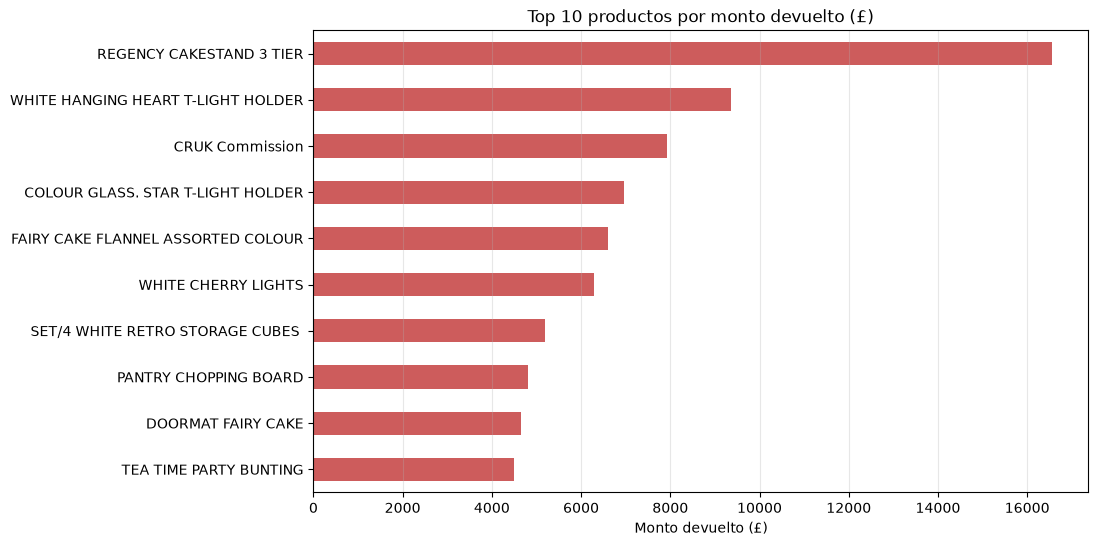

Description
REGENCY CAKESTAND 3 TIER             16,545.30
WHITE HANGING HEART T-LIGHT HOLDER    9,369.40
CRUK Commission                       7,933.43
COLOUR GLASS. STAR T-LIGHT HOLDER     6,966.66
FAIRY CAKE FLANNEL ASSORTED COLOUR    6,614.37
WHITE CHERRY LIGHTS                   6,297.55
SET/4 WHITE RETRO STORAGE CUBES       5,187.65
PANTRY CHOPPING BOARD                 4,803.06
DOORMAT FAIRY CAKE                    4,650.20
TEA TIME PARTY BUNTING                4,490.50
Name: TotalPrice, dtype: float64

También en top ventas: {'WHITE HANGING HEART T-LIGHT HOLDER', 'REGENCY CAKESTAND 3 TIER'}


In [32]:
no_productos = ['Manual', 'POSTAGE', 'Discount', 'CARRIAGE']
dev_productos = devoluciones[~devoluciones['Description'].isin(no_productos)]

top_dev = dev_productos.groupby('Description')['TotalPrice'].sum().nsmallest(10).abs()

top_dev.sort_values().plot(kind='barh', figsize=(10, 6), color='indianred')
plt.title('Top 10 productos por monto devuelto (£)')
plt.xlabel('Monto devuelto (£)')
plt.ylabel('')
plt.grid(axis='x', alpha=0.3)
plt.show()

print(top_dev)
print("\nTambién en top ventas:", set(top_dev.index) & set(top_ingresos.index))

> **Hallazgo:**
> - **Peso:** se devolvieron £839.160, el 4,9% de los ingresos, en 7.899 facturas de devolución.
> - **Monto vs filas:** en la sección 14 las devoluciones eran el 2,30% de las filas, pero en dinero pesan el 4,9%. Se devuelven líneas de más valor que la venta promedio.
> - **Clientes:** 2.572 de 5.878 clientes (43,8%) hicieron al menos una devolución. Es una práctica habitual, no de unos pocos clientes.
> - **Productos:** los dos más devueltos son REGENCY CAKESTAND 3 TIER (£16.545) y WHITE HANGING HEART T-LIGHT HOLDER (£9.369), que también son los dos más vendidos. Se devuelven más porque se venden más.
> - **Registros que no son productos:** se excluyeron `Manual`, `POSTAGE`, `Discount`, `CARRIAGE` y `CRUK Commission` (comisión benéfica).
> - **Interpretación:** las devoluciones son bajas en relación con los ingresos y no muestran un producto problemático aislado.

## 23. Clientes top

In [36]:
ingresos_cliente = ventas.groupby('Customer ID')['TotalPrice'].sum().sort_values(ascending=False)

top20 = int(len(ingresos_cliente) * 0.2)
pct_top20 = ingresos_cliente.head(top20).sum() / ingresos_cliente.sum() * 100

print(f"El 20% de los clientes ({top20:,}) genera el {pct_top20:.1f}% de los ingresos")

El 20% de los clientes (1,175) genera el 76.9% de los ingresos


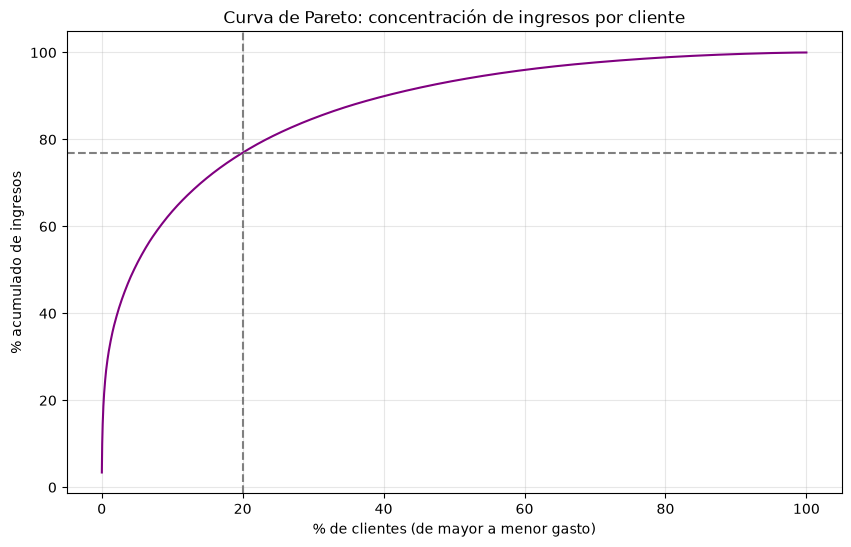

In [37]:
acumulado = ingresos_cliente.cumsum() / ingresos_cliente.sum() * 100
pct_clientes = np.arange(1, len(acumulado) + 1) / len(acumulado) * 100

plt.figure(figsize=(10, 6))
plt.plot(pct_clientes, acumulado.values, color='purple')
plt.axvline(20, color='gray', linestyle='--')
plt.axhline(pct_top20, color='gray', linestyle='--')
plt.title('Curva de Pareto: concentración de ingresos por cliente')
plt.xlabel('% de clientes (de mayor a menor gasto)')
plt.ylabel('% acumulado de ingresos')
plt.grid(alpha=0.3)
plt.show()